### TEL351 – Seminario de Telemática I
# Clase 9: Semantic Search, Knowledge Graphs, Topics Models and Concept Modeling
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

# Búsqueda en la web

Al principio, los motores de búsqueda eran léxicos, es decir, buscaban coincidencias literales de las palabras en la consulta, y solo devolvían enlaces que contenían la consulta exacta sin comprender el significado real de la solicitud.

<div align="center">
    <img src="img/busqueda.avif" alt="" width="25%" align="center" />
</div>

# Semántica

La semántica es una rama de la lingüística que estudia los significados de las palabras.

<div align="center">
    <img src="img/semantica.jpg" alt="" width="40%" align="center" />
</div>

# Búsqueda Semántica

La búsqueda semántica proporciona una comprensión del lenguaje natural e identifica resultados que tienen el mismo significado, no necesariamente las mismas palabras clave.

Búsqueda Léxica: "how rich is the guy who played harry potter?"

<div align="center">
    <img src="img/lexic-search.png" alt="" width="40%" align="center" />
</div>

Búsqueda Semántica: how rich is the guy who played harry potter?

<div align="center">
    <img src="img/semantic-search.png" alt="" width="40%" align="center" />
</div>

# Knowledge Graphs

Los grafos semánticos, también conocidos como grafos de conocimiento o redes semánticas, construyen una red con relaciones semánticas que conectan los nodos. Generalmente, a partir de las relaciones aprendidas de los embeddings, es posible obtener conocimiento y realizar búsquedas semánticas.

<div align="center">
    <img src="img/knowledge-graph.jpg" alt="" width="50%" align="center" />
</div>

# Breve historia de la búsqueda web

- En 2012, Google introduce los grafos de conocimiento como primer intento para transformar la búsqueda de palabras clave en búsquedas semánticas.

- En 2013, Google lanza Hummingbird para garantizar que las páginas que coincidan con el significado y el contexto de la búsqueda tengan mejor ranking.

- En 2015, Google lanza RankBrain, un sistema de aprendizaje automático que es un analizador de consultas inteligente y rankea páginas.

- En 2019, Google presenta BERT lo que permite al buscador comprender mejor la intención y el contexto de búsqueda. Según Google, esto representó el avance más significativo en los últimos cinco años y uno de los mayores en la historia de las búsquedas.

In [1]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

In [2]:
# Load the IMDb dataset
data = pd.read_csv("IMDB-Movie-Data.csv")

In [3]:
data.head()

,Rank,Title,Genre,Description,Director,Actors,Year,Runtime (Minutes),Rating,Votes,Revenue (Millions),Metascore
0,1,Guardians of the Galaxy,"Action,Adventure,Sci-Fi",A group of intergalactic criminals are forced ...,James Gunn,"Chris Pratt, Vin Diesel, Bradley Cooper, Zoe S...",2014,121,8.1,757074,333.13,76.0
1,2,Prometheus,"Adventure,Mystery,Sci-Fi","Following clues to the origin of mankind, a te...",Ridley Scott,"Noomi Rapace, Logan Marshall-Green, Michael Fa...",2012,124,7.0,485820,126.46,65.0
2,3,Split,"Horror,Thriller",Three girls are kidnapped by a man with a diag...,M. Night Shyamalan,"James McAvoy, Anya Taylor-Joy, Haley Lu Richar...",2016,117,7.3,157606,138.12,62.0
3,4,Sing,"Animation,Comedy,Family","In a city of humanoid animals, a hustling thea...",Christophe Lourdelet,"Matthew McConaughey,Reese Witherspoon, Seth Ma...",2016,108,7.2,60545,270.32,59.0
4,5,Suicide Squad,"Action,Adventure,Fantasy",A secret government agency recruits some of th...,David Ayer,"Will Smith, Jared Leto, Margot Robbie, Viola D...",2016,123,6.2,393727,325.02,40.0


In [4]:
# Select relevant columns
df = data[["Title", "Actors", "Director"]]

In [5]:
df

,Title,Actors,Director
0,Guardians of the Galaxy,"Chris Pratt, Vin Diesel, Bradley Cooper, Zoe S...",James Gunn
1,Prometheus,"Noomi Rapace, Logan Marshall-Green, Michael Fa...",Ridley Scott
2,Split,"James McAvoy, Anya Taylor-Joy, Haley Lu Richar...",M. Night Shyamalan
3,Sing,"Matthew McConaughey,Reese Witherspoon, Seth Ma...",Christophe Lourdelet
4,Suicide Squad,"Will Smith, Jared Leto, Margot Robbie, Viola D...",David Ayer
...,...,...,...
995,Secret in Their Eyes,"Chiwetel Ejiofor, Nicole Kidman, Julia Roberts...",Billy Ray
996,Hostel: Part II,"Lauren German, Heather Matarazzo, Bijou Philli...",Eli Roth
997,Step Up 2: The Streets,"Robert Hoffman, Briana Evigan, Cassie Ventura,...",Jon M. Chu
998,Search Party,"Adam Pally, T.J. Miller, Thomas Middleditch,Sh...",Scot Armstrong


In [6]:
def build_semantic_graph(df, movies):
    graph = nx.DiGraph()
    # Add nodes and edges based on the dataset
    for _, row in df.iterrows():
        movie = row["Title"]
        actors = row["Actors"].split(", ")
        director = row["Director"]

        if movie in movies:

            graph.add_node(movie, type="movie")
            graph.add_node(director, type="director")

            for actor in actors:
                graph.add_node(actor, type="actor")
                graph.add_edge(actor, movie, relationship="actúa en")
                graph.add_edge(director, movie, relationship="dirige")
    return graph

In [7]:
movies = df['Title'].tolist()

In [8]:
full_graph = build_semantic_graph(df, movies)

In [9]:
print(full_graph)

DiGraph with 3627 nodes and 4625 edges


In [10]:
# Calculate degrees for each node
degree_dict = dict(full_graph.degree())

# Exclude nodes of type "movie" from the degree dictionary
degree_dict = {node: degree for node, degree in degree_dict.items() if full_graph.nodes[node]['type'] != 'movie'}

# Sort nodes by degree
sorted_nodes_by_degree = sorted(degree_dict.items(), key=lambda x: x[1], reverse=True)

In [11]:
# Get movies for the actor with the highest degree
top_actor = sorted_nodes_by_degree[0][0]
top_movies = [succ for succ in full_graph.successors(top_actor) 
              if full_graph.edges[(top_actor, succ)]['relationship'] == 'actúa en']
print(top_actor,top_movies)

Mark Wahlberg ['Patriots Day', 'Deepwater Horizon', 'The Departed', 'Transformers: Age of Extinction', 'Lone Survivor', 'The Other Guys', 'Shooter', 'The Happening', "Daddy's Home", 'The Lovely Bones', 'Ted 2', 'Pain & Gain', 'Ted', 'The Fighter', 'The Gambler']


In [12]:
graph = build_semantic_graph(df, top_movies)

In [13]:
node_colors = {"movie": "lightblue", "director": "lightgreen", "actor": "lightpink"}

In [14]:
node_types = nx.get_node_attributes(graph, "type")

In [15]:
node_color_list = [node_colors[node_types[node]] for node in graph.nodes()]

In [16]:
def plot_graph(graph, node_color_list):
    plt.figure(figsize=(20,10))
    pos = nx.spring_layout(graph, seed=42)
    nx.draw_networkx(
        graph,
        pos,
        with_labels=True,
        labels={node: node.replace(" ", "\n") for node in graph.nodes()},
        node_size=2000,
        node_color=node_color_list,
        font_size=10,
        font_color="black", 
    )
    # Extract edge labels from the 'relationship' attribute
    edge_labels = {(u, v): data['relationship'] for u, v, data in graph.edges(data=True) if 'relationship' in data}
    
    # Draw edge labels
    edge_label_pos = {k: (v[0], v[1] - 0.08) for k, v in pos.items()}  # Adjust label position
    nx.draw_networkx_edge_labels(graph, pos=edge_label_pos, edge_labels=edge_labels, font_size=8)
    
    plt.axis('off')
    plt.show()

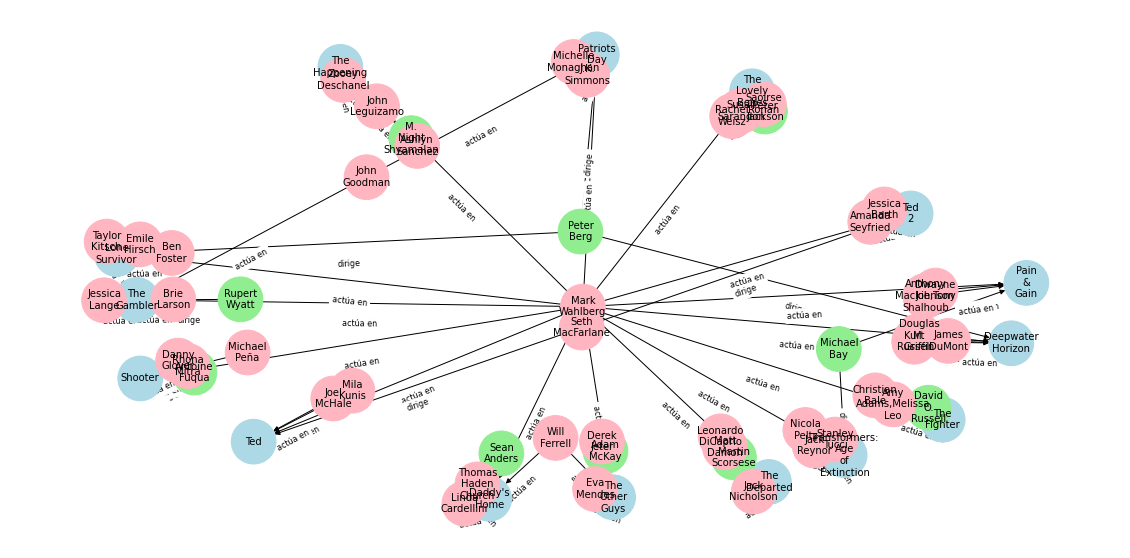

In [17]:
plot_graph(graph, node_color_list)

# Indexación Semántica Latente (LSI)

La indexación semántica latente es una técnica que se utiliza para encontrar relaciones semánticas latentes entre términos y documentos. Asume que las palabras con significado similar, aparecen en documentos similares. Por lo tanto, los documentos que contienen muchas palabras en común son semánticamente cercanos.

## Algoritmo LSI

In [12]:
import gensim
from gensim.parsing.preprocessing import preprocess_documents

In [13]:
df = pd.read_csv('movie_plots.csv', sep=',')
# Sampling para eficiencia: solo las películas del año 2000 en adelante
df = df[df['Year'] >= 2000]
text_corpus = df['Plot'].values

In [14]:
# Limpieza y normalización del texto.
processed_corpus = preprocess_documents(text_corpus)

In [15]:
# Se crea el vocabulario del corpus asignando identificadores a todas las palabras únicas y se almacena su frecuencia
dictionary = gensim.corpora.Dictionary(processed_corpus)

### 1. Creación de la Matriz de Términos y Documentos

Se construye una matriz donde las filas representan términos y las columnas representan documentos. Cada celda contiene un valor que indica la frecuencia de un término en un documento. Esta matriz es conocida como la matriz término-documento.

|Palabra/Documento|	Doc 1|	Doc 2|	Doc 3|
|---|---|---|---|
|"perro"|	2|	0|	1|
|"gato"	|1|	2|	0|
|"animal"|	1|	1|	3|

In [16]:
bow_corpus = [dictionary.doc2bow(text) for text in processed_corpus]

In [17]:
# Se construye la matriz de términos usando el modelo TF-IDF
tfidf = gensim.models.TfidfModel(bow_corpus, smartirs='npu')
corpus_tfidf = tfidf[bow_corpus]

### 2. Descomposición en Valores Singulares

Se realiza una descomposición en valores singulares (SVD, por sus siglas en inglés) de la matriz. La descomposición SVD reduce la matriz en tres matrices más pequeñas: $U$, $Σ$ y $V^T$. Aquí, $U$ representa la relación entre términos y conceptos, $Σ$ contiene los valores singulares que indican la importancia de los conceptos y $V^T$ representa la relación entre conceptos y documentos.

<div align="center">
<img src="img/Full_SVD.png" alt="" width="40%" align="center" />
</div>

### 3. Reducción de Dimensionalidad

Para reducir la dimensionalidad, se truncan las matrices $U$, $Σ$ y $V^T$ al retener solo los valores singulares más importantes. Esto tiene el efecto de eliminar el ruido y la redundancia de los datos, al tiempo que mantiene la estructura semántica que hay detrás. Se identifican patrones que agrupan términos y documentos en conceptos similares, conocidos como temas latentes.

<div align="center">
<img src="img/SVD.png" alt="" width="60%" align="center" />
</div>

In [18]:
# reducción de dimensionalidad con 300 tópicos o dimensiones latentes
lsi = gensim.models.LsiModel(corpus_tfidf, num_topics=300, random_seed=1)
index = gensim.similarities.MatrixSimilarity(lsi[corpus_tfidf])

In [ ]:
# Save the LSI model
# lsi.save("model/lsi_model")

In [24]:
# Load the LSI model
lsi = gensim.models.LsiModel.load("model/lsi_model")
index = gensim.similarities.MatrixSimilarity(lsi[corpus_tfidf])

### Búsqueda Semántica

Una vez que se ha realizado el análisis, LSI permite realizar búsquedas semánticas en la colección de documentos. Las consultas se proyectan en el espacio semántico reducido y se comparan con los temas latentes para recuperar documentos relevantes.

In [19]:
def semantic_search(prompt, k=10):
    new_doc = gensim.parsing.preprocessing.preprocess_string(prompt)
    new_vec = dictionary.doc2bow(new_doc)
    vec_bow_tfidf = tfidf[new_vec]
    vec_lsi = lsi[vec_bow_tfidf]
    sims = index[vec_lsi]    
    movie_names = []
    for movie in sorted(enumerate(sims), key=lambda item: -item[1])[:k]:
        movie_names.append (
            {
                'Relevance': round((movie[1] * 100),2),
                'Movie Title': df['Title'].iloc[movie[0]],
                'Movie Plot': df['Plot'].iloc[movie[0]]
            }
        )       
    return pd.DataFrame(movie_names, columns=['Relevance','Movie Title','Movie Plot'])

In [26]:
semantic_search('blonde bride goes to Japan and kills many people')

,Relevance,Movie Title,Movie Plot
0,65.74,Kill Bill Volume 1,"A woman in a wedding dress, the Bride, lies wo..."
1,65.74,Kill Bill Volume 2,"A woman in a wedding dress, the Bride, lies wo..."
2,62.33,The Little House,The film is set in the 1930s and 1940s in Japa...
3,60.28,A Boy and His Samurai,"Based on a manga by Gen Araki,[1] the film chr..."
4,55.60,Ōoku,"In an alternative timeline of feudal Japan, a ..."
5,55.60,Ōoku: Emonnosuke Tsunayoshi Hen,"In an alternative timeline of feudal Japan, a ..."
6,54.32,Wara no Tate,Ninagawa was a powerful man in Japanese politi...
7,52.75,Code Geass Lelouch of the Resurrection the Mov...,The story is set in an alternative timeline wh...
8,51.01,Desert Moon,The film's main theme is the conflict between ...
9,50.25,About Love,"In Tokyo, he is a Chinese computer graphic art..."


In [27]:
semantic_search('infiltrate minds with different levels of dreams to implant an idea')

,Relevance,Movie Title,Movie Plot
0,72.09,Paprika,"In the near future, a revolutionary new psycho..."
1,68.36,Dream,The story runs around a retired Army officer w...
2,64.73,Let's Dance,"Suhani, a passionate young dancer, dreams of b..."
3,62.93,Waking Life,Waking Life is about an unnamed[3] young man l...
4,60.80,Zegapain ADP,"Kyo Sogoru, a high school boy living in a city..."
5,59.80,Write or Dance,The story of an aspiring novelist who experien...
6,59.33,Chalo Paltai,The film revolves around the relations between...
7,59.05,Bicycle Kick,"Rubayet, a 19-year-old boy studying the first ..."
8,58.95,Taurus,The second film of the director-conceived cine...
9,58.57,Ant Story,Everyday on the way back to his suburban home ...


In [28]:
semantic_search('annoying girl from a candy racing game who glitches')

,Relevance,Movie Title,Movie Plot
0,77.25,Rush,James Hunt and Niki Lauda are two highly skill...
1,75.53,Wreck-It Ralph,When Litwak's Family Fun Center & Arcade close...
2,74.73,Speed Angels,Taxi driver Xiaoyi (Tang Wei) is discovered by...
3,74.42,Biker Boyz,In the world of underground motorcycle drag ra...
4,71.57,Bhaag Milkha Bhaag,The film starts in the 1960 Summer Olympics in...
5,71.34,Speed Racer,Speed Racer is an 18-year-old whose life and l...
6,69.79,50 to 1,A misfit group of New Mexico cowboys find them...
7,69.65,Champ,Two damaged souls race together for the race o...
8,68.96,Saint Ralph,Ralph Walker is a teenager attending a Catholi...
9,68.39,Cars 3,"Lightning McQueen, now a seven-time Piston Cup..."


In [29]:
semantic_search('a group of dumped toys embark on a journey to reunite with their owner')

,Relevance,Movie Title,Movie Plot
0,60.67,Toy Story 3,Seventeen-year-old Andy[11] is about to leave ...
1,51.82,Into the Forest,"In the near future, two teenage sisters, Nell ..."
2,50.07,The Road,A man and his young son struggle to survive af...
3,49.62,This is England,"In 1983, 12-year-old Shaun gets into a fight a..."
4,49.28,Thanks Maa,"A 12-year-old street kid named Municipality, w..."
5,48.75,Bhoomiyude Avakashikal,Mohanachandran Nair (Kailash) is a Malayali yo...
6,48.53,Iti Mrinalini,"Mrinalini, an ageing actress, writes a suicide..."
7,48.48,Angels in Stardust,The film centers around a small-town girl (Mic...
8,48.38,72 Mile - Ek Pravas,A young boy decides to escape from his boardin...
9,47.94,Flutter,"A quiet film without color, a boy and a girl m..."


# REBEL (Relation Extraction)

Modelo neuronal de lenguaje que identifica entidades y extrae las relaciones. Por lo tanto, permite construir un grafo de conocimiento a partir de cualquier texto.

In [30]:
from transformers import AutoModelForSeq2SeqLM, AutoTokenizer

In [31]:
tokenizer = AutoTokenizer.from_pretrained("Babelscape/rebel-large")

In [32]:
model = AutoModelForSeq2SeqLM.from_pretrained("Babelscape/rebel-large")

In [33]:
def extract_relations_from_model_output(text):
    relations = []
    relation, subject, relation, object_ = '', '', '', ''
    text = text.strip()
    current = 'x'
    text_replaced = text.replace("<s>", "").replace("<pad>", "").replace("</s>", "")
    for token in text_replaced.split():
        if token == "<triplet>":
            current = 't'
            if relation != '':
                relations.append({
                    'head': subject.strip(),
                    'type': relation.strip(),
                    'tail': object_.strip()
                })
                relation = ''
            subject = ''
        elif token == "<subj>":
            current = 's'
            if relation != '':
                relations.append({
                    'head': subject.strip(),
                    'type': relation.strip(),
                    'tail': object_.strip()
                })
            object_ = ''
        elif token == "<obj>":
            current = 'o'
            relation = ''
        else:
            if current == 't':
                subject += ' ' + token
            elif current == 's':
                object_ += ' ' + token
            elif current == 'o':
                relation += ' ' + token
    if subject != '' and relation != '' and object_ != '':
        relations.append({
            'head': subject.strip(),
            'type': relation.strip(),
            'tail': object_.strip()
        })
    return relations

In [34]:
class KB():
    def __init__(self):
        self.relations = []

    def are_relations_equal(self, r1, r2):
        return all(r1[attr] == r2[attr] for attr in ["head", "type", "tail"])

    def exists_relation(self, r1):
        return any(self.are_relations_equal(r1, r2) for r2 in self.relations)

    def add_relation(self, r):
        if not self.exists_relation(r):
            self.relations.append(r)
    
    def get_relations(self):
        relations = []

    def print(self):
        print("Relations:")
        for r in self.relations:
            print(f"  {r}")

In [35]:
def from_text_to_kb(text, verbose=False):
    kb = KB()

    # Tokenizer text
    model_inputs = tokenizer(text, max_length=512, padding=True, truncation=True,
                            return_tensors='pt')
    if verbose:
        print(f"Num tokens: {len(model_inputs['input_ids'][0])}")

    # Generate
    gen_kwargs = {
        "max_length": 216,
        "length_penalty": 0,
        "num_beams": 3,
        "num_return_sequences": 3
    }
    generated_tokens = model.generate(
        **model_inputs,
        **gen_kwargs,
    )
    decoded_preds = tokenizer.batch_decode(generated_tokens, skip_special_tokens=False)

    # create kb
    for sentence_pred in decoded_preds:
        relations = extract_relations_from_model_output(sentence_pred)
        for r in relations:
            kb.add_relation(r)

    return kb

In [36]:
text = """Napoleon Bonaparte (born Napoleone di Buonaparte; 15 August 1769 – 5 May 1821), and later known by his regnal name Napoleon I, 
was a French military and political leader who rose to prominence during the French Revolution and led several successful campaigns during the Revolutionary Wars. 
He was the de facto leader of the French Republic as First Consul from 1799 to 1804. 
As Napoleon I, he was Emperor of the French from 1804 until 1814 and again in 1815. 
Napoleon's political and cultural legacy has endured, and he has been one of the most celebrated and controversial leaders in world history."""

In [37]:
kb = from_text_to_kb(text)

In [38]:
def build_rebel_graph(relations):

    # Create a NetworkX directed graph (DiGraph)
    graph = nx.DiGraph()

    # Add nodes and directed edges based on relations
    for relation in relations:
        head = relation['head']
        tail = relation['tail']
        relationship_type = relation['type']

        graph.add_node(head, type='entity')
        graph.add_node(tail, type='entity')

        graph.add_edge(tail, head, relationship=relationship_type)
    
    return graph

In [39]:
knowledge_graph = build_rebel_graph(kb.relations)

In [40]:
def plot_knowledge_graph(graph, title="Knowledge graph"):
    pos = nx.spring_layout(graph, seed=42)
    node_labels = {node: node.replace(" ", "\n") for node in graph.nodes()}
    edge_labels = {(u, v): data['relationship'] for u, v, data in graph.edges(data=True)}

    plt.figure(figsize=(20, 10))
    nx.draw_networkx(graph, pos, node_size=3500, with_labels=False, node_color='lightblue', arrowsize=20)

    nx.draw_networkx_labels(graph, pos, labels=node_labels, font_size=10, font_color='black')
    nx.draw_networkx_edge_labels(graph, pos, edge_labels=edge_labels, font_size=10)

    plt.title(title, fontsize=24)
    plt.axis('off')
    plt.show()

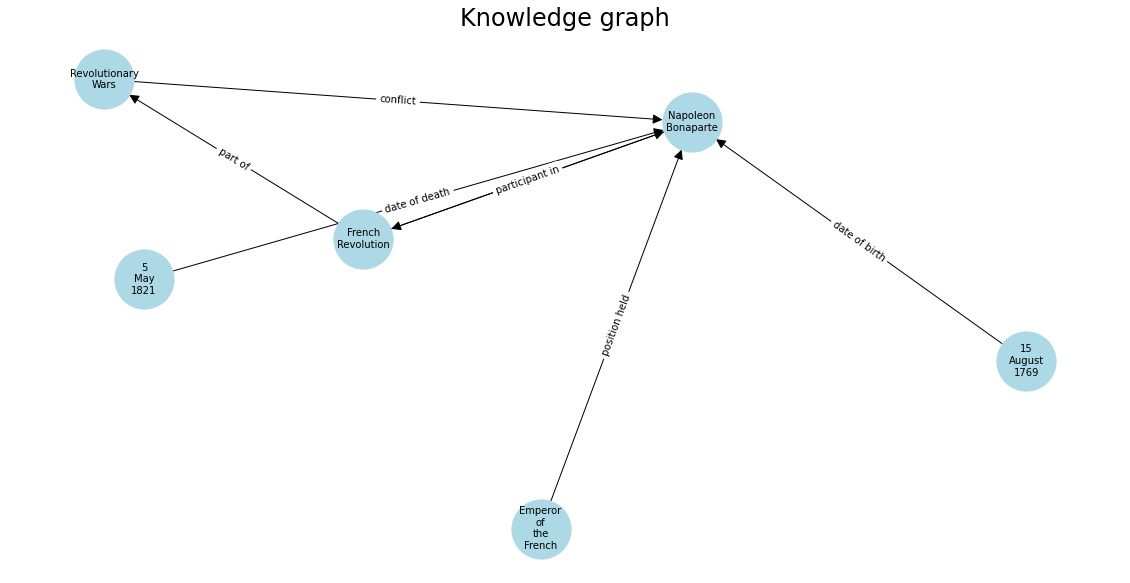

In [41]:
plot_knowledge_graph(knowledge_graph)

# Topics Models

Topic modeling es un método no supervisado para identificar temas abstractos dentro de un conjunto de datos. La forma más común de modelar temas es usar algoritmos de clustering para agrupar los nodos con la proximidad más cercana.

<div align="center">
    <img src="img/topics.png" alt="" width="30%" align="center" />
</div>

## BERTopic

Hoy en día existe una serie de excelentes bibliotecas de modelado de tópicos en Python, como por ejemplo BERTopic que usa transformers de oraciones para codificar datos en vectores, UMAP para reducción de dimensionalidad y HDBSCAN para agrupar nodos.

<div align="center">
    <img src="img/BERTopic.png" alt="" width="30%" align="center" />
</div>

In [1]:
import re
import pandas as pd

In [2]:
trump = pd.read_csv('tweets.csv')
trump.text = trump.apply(lambda row: re.sub(r"http\S+", "", row.text).lower(), 1)
trump.text = trump.apply(lambda row: " ".join(filter(lambda x:x[0]!="@", row.text.split())), 1)
trump.text = trump.apply(lambda row: " ".join(re.sub("[^a-zA-Z]+", " ", row.text).split()), 1)
trump = trump.loc[(trump.isRetweet == "f") & (trump.text != ""), :]
timestamps = trump.date.to_list()
tweets = trump.text.to_list()


In [3]:
tweets[:10]

['republicans and democrats have both created our economic problems',
 'i was thrilled to be back in the great city of charlotte north carolina with thousands of hardworking american patriots who love our country cherish our values respect our laws and always put america first thank you for a wonderful evening kag',
 'the unsolicited mail in ballot scam is a major threat to our democracy amp the democrats know it almost all recent elections using this system even though much smaller amp with far fewer ballots to count have ended up being a disaster large numbers of missing ballots amp fraud',
 'getting a little exercise this morning',
 'thank you elise',
 'as per your request joe',
 'the threshold identification of ballots is turning out to be even bigger than originally anticipated a very large number of ballots are impacted stay tuned',
 'i m running as a proud democrat for the senate sleepy joe biden today it s only going to get worse it is not sustainable for our county china will 

In [4]:
# !pip install bertopic

In [5]:
from bertopic import BERTopic

In [ ]:
topic_model = BERTopic(verbose=True)
topics, probs = topic_model.fit_transform(tweets)

Visualizar tópicos:

In [7]:
topic_model.visualize_barchart()

Buscar tópicos similares:

In [8]:
def find_similar_topics(model, topic, n=5):
    similar_topics, similarity = model.find_topics(topic, top_n=n)
    for t,s in zip(similar_topics,similarity):
        print(f"Topic: {t} ({round(s*100,2)}%)")
        for word,sim in model.get_topic(t):
            print(f" {word} ({round(sim*100,2)}%)",end=',')
        print("\n")

In [9]:
find_similar_topics(topic_model, "biden")

Topic: 36 (67.85%)
 biden (4.87%), joe (3.75%), sleepy (2.04%), hunter (1.41%), wins (1.36%), politician (0.88%), corrupt (0.81%), china (0.8%), basement (0.66%), foreign (0.54%),

Topic: 487 (50.64%)
 biden (6.53%), police (5.11%), enforcement (4.13%), joe (3.7%), law (3.59%), rioters (3.14%), looters (2.95%), defund (2.54%), blaming (2.07%), heroes (2.02%),

Topic: 291 (47.64%)
 fracking (13.8%), energy (5.45%), pennsylvania (5.38%), biden (4.6%), ban (4.4%), abolish (3.51%), vowed (2.83%), gas (2.31%), joe (2.31%), harris (2.14%),

Topic: 443 (42.77%)
 swine (10.2%), flu (9.9%), handling (5.21%), biden (3.52%), lethal (3.27%), died (3.15%), joe (3.14%), disaster (2.87%), covid (2.56%), response (2.38%),

Topic: 425 (42.2%)
 negotiating (7.01%), negotiator (5.28%), negotiators (5.28%), republicans (3.1%), secretive (2.69%), settles (2.69%), ford (2.63%), negotiate (2.62%), wewantmitt (2.53%), cunning (2.53%),



In [10]:
find_similar_topics(topic_model, "vaccine")

Topic: 205 (72.43%)
 vaccines (8.65%), vaccine (8.13%), therapeutics (2.41%), fda (2.32%), moderna (2.02%), distribution (1.95%), miracle (1.77%), speed (1.44%), administered (1.4%), five (1.34%),

Topic: 304 (69.14%)
 autism (8.87%), vaccinations (6.27%), child (6.16%), doses (5.64%), vaccine (5.63%), shots (5.03%), dose (5.02%), vaccines (4.49%), spread (3.88%), massive (3.66%),

Topic: 32 (40.13%)
 coronavirus (4.0%), virus (2.49%), covid (2.32%), deaths (1.18%), cases (1.09%), mortality (1.08%), testing (1.01%), china (0.92%), rate (0.85%), news (0.66%),

Topic: 443 (36.88%)
 swine (10.2%), flu (9.9%), handling (5.21%), biden (3.52%), lethal (3.27%), died (3.15%), joe (3.14%), disaster (2.87%), covid (2.56%), response (2.38%),

Topic: 61 (36.6%)
 ebola (13.29%), africa (4.36%), flights (2.88%), west (2.31%), infected (2.06%), ban (1.56%), cdc (1.42%), travel (1.38%), patient (1.26%), patients (1.19%),



Tópicos en el tiempo:

In [ ]:
topics_over_time = topic_model.topics_over_time(tweets, timestamps, nr_bins=20)

In [12]:
topic_model.visualize_topics_over_time(topics_over_time, top_n_topics=10)


# Concept Modeling

El modelado de conceptos es la generalización del modelado de tópicos a imágenes y texto.

<div align="center">
    <img src="img/Concept.png" alt="" width="50%" align="center" />
</div>

In [13]:
# !pip install datasets

In [14]:
from datasets import load_dataset

In [ ]:
ds = load_dataset("maderix/flickr_bw_rgb")
images = ds["train"]["image"]
docs = ds["train"]["caption"]

In [16]:
from bertopic.representation import VisualRepresentation

In [17]:
visual_model = VisualRepresentation()

In [18]:
representation_model = {
   "Visual_Aspect":  visual_model,
}

In [19]:
multimodal_model = BERTopic(representation_model=representation_model, verbose=True)

In [ ]:
topics, probs = multimodal_model.fit_transform(documents=docs, images=images)

In [21]:
import base64
from io import BytesIO
from IPython.display import HTML

In [22]:
def image_base64(im):
    if isinstance(im, str):
        im = get_thumbnail(im)
    with BytesIO() as buffer:
        im.save(buffer, 'jpeg')
        return base64.b64encode(buffer.getvalue()).decode()

In [23]:
def image_formatter(im):
    return f'<img src="data:image/jpeg;base64,{image_base64(im)}">'

In [24]:
df = multimodal_model.get_topic_info().drop("Representative_Docs", 1).drop("Name", 1)

In [25]:
df

,Topic,Count,Representation,Visual_Aspect
0,-1,2034,"[of, and, photograph, black, the, with, white,...",<PIL.Image.Image image mode=RGB size=600x600 a...
1,0,482,"[bike, bicycle, riding, motorcycle, dirt, pers...",<PIL.Image.Image image mode=RGB size=600x600 a...
2,1,213,"[woman, her, lady, skirt, wearing, front, hair...",<PIL.Image.Image image mode=RGB size=600x600 a...
3,2,128,"[women, two, skirts, one, dresses, sitting, th...",<PIL.Image.Image image mode=RGB size=600x600 a...
4,3,124,"[girl, dress, pink, young, her, little, flower...",<PIL.Image.Image image mode=RGB size=600x600 a...
...,...,...,...,...
128,127,11,"[kids, walking, children, walk, catwalk, fashi...",<PIL.Image.Image image mode=RGB size=600x600 a...
129,128,11,"[balls, pink, ball, sponge, girl, eight, holdi...",<PIL.Image.Image image mode=RGB size=600x600 a...
130,129,11,"[fishing, fisherman, pole, fish, line, fully, ...",<PIL.Image.Image image mode=RGB size=600x600 a...
131,130,10,"[field, run, grassy, shouting, cycle, dogs, th...",<PIL.Image.Image image mode=RGB size=600x600 a...


,Topic,Count,Representation,Visual_Aspect
11,10,91,"[rock, climbing, climber, mountain, cliff, scaling, climbs, man, climbers, face]",
13,12,72,"[basketball, player, court, miami, men, teams, shooting, shot, team, playing]",
15,14,69,"[bird, flying, pigeons, birds, flies, wings, crane, flight, duck, water]",

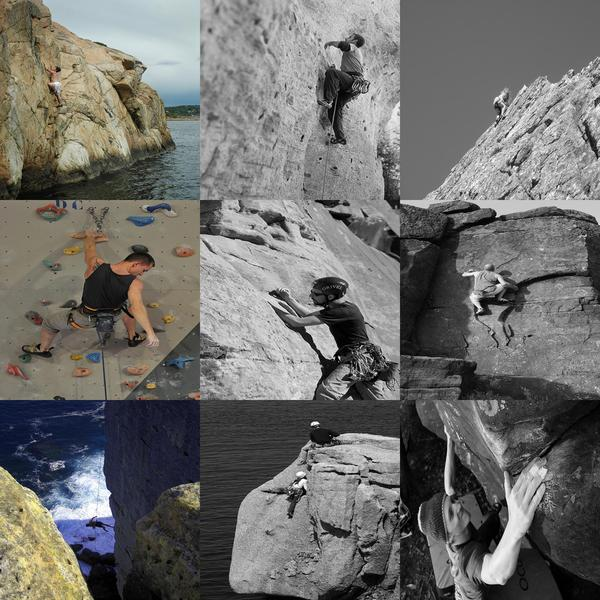
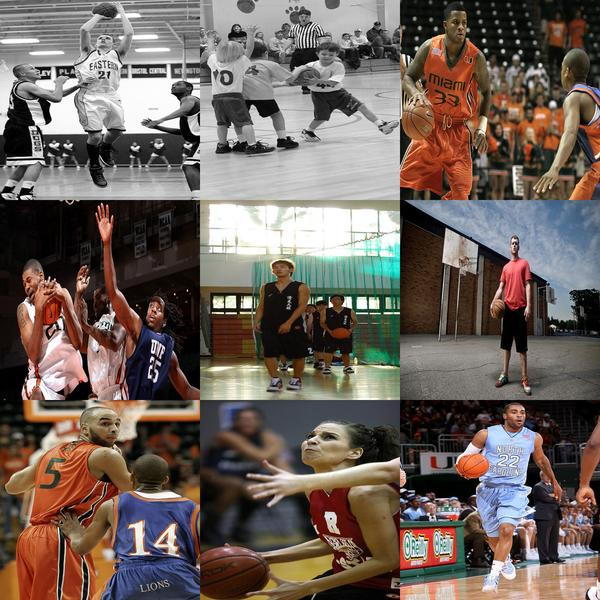
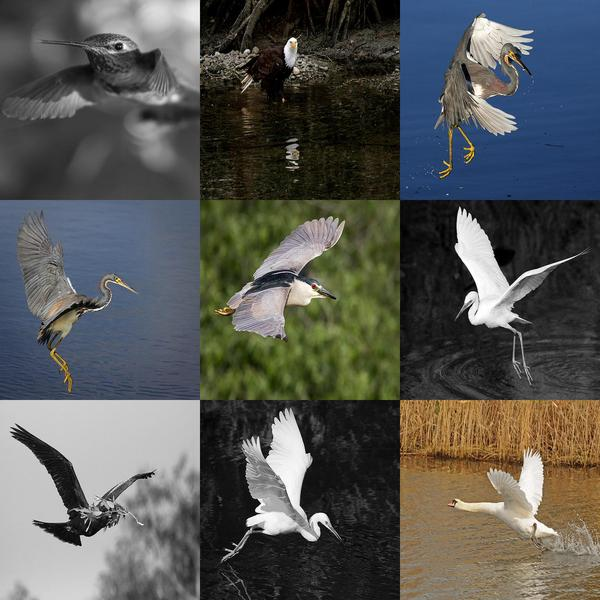

In [39]:
HTML(df.loc[[11,13,15]].to_html(formatters={'Visual_Aspect': image_formatter}, escape=False))

In [27]:
def search_concepts(search_word):
    result = df[df['Representation'].apply(lambda x: search_word in x)]
    return HTML(result.to_html(formatters={'Visual_Aspect': image_formatter}, escape=False))

,Topic,Count,Representation,Visual_Aspect
34,33,44,"[tennis, player, racket, racquet, hitting, ball, hits, headband, badminton, orange]",
105,104,16,"[tennis, ball, mouth, its, catch, catches, dog, jumps, tan, amid]",

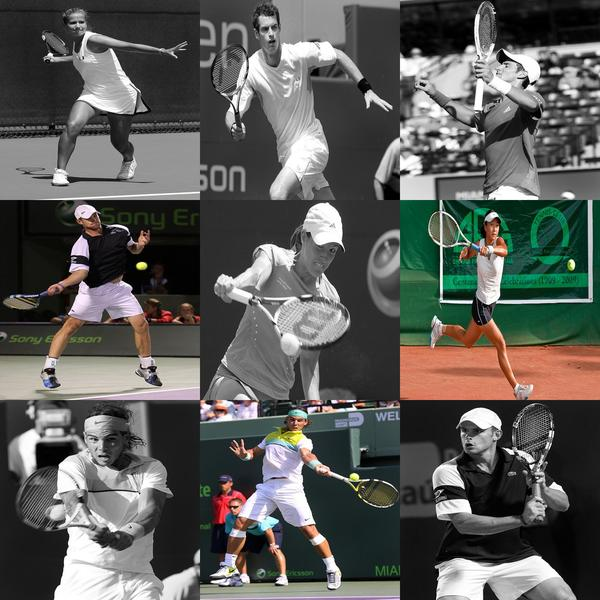
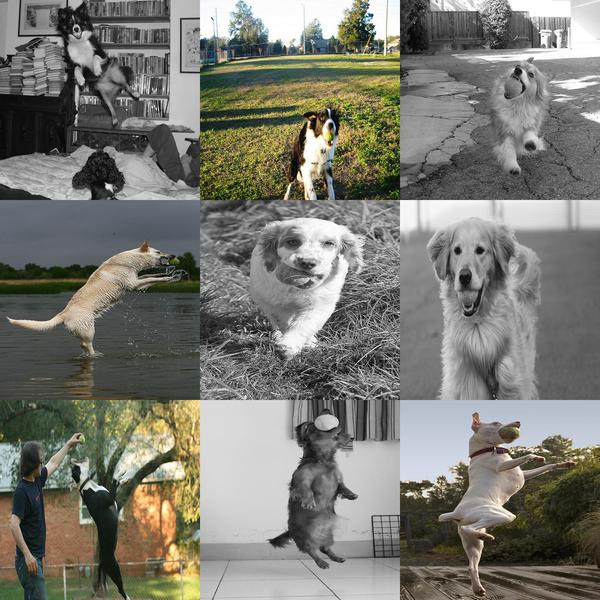

In [28]:
search_concepts('tennis')

# Generación de conceptos

¿Qué pasaría si no tenemos imágenes etiquetadas para generar conceptos?

In [29]:
from transformers import VisionEncoderDecoderModel, ViTImageProcessor, AutoTokenizer
import torch
from PIL import Image
import matplotlib.pyplot as plt

In [30]:
model = VisionEncoderDecoderModel.from_pretrained("nlpconnect/vit-gpt2-image-captioning")
feature_extractor = ViTImageProcessor.from_pretrained("nlpconnect/vit-gpt2-image-captioning")
tokenizer = AutoTokenizer.from_pretrained("nlpconnect/vit-gpt2-image-captioning")

In [31]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device);

In [32]:
def caption(image_path, max_length = 16, num_beams = 4):
    gen_kwargs = {"max_length": max_length, "num_beams": num_beams}
    images = []

    i_image = Image.open(image_path)
    if i_image.mode != "RGB":
        i_image = i_image.convert(mode="RGB")

    images.append(i_image)

    pixel_values = feature_extractor(images=images, return_tensors="pt").pixel_values
    pixel_values = pixel_values.to(device)

    output_ids = model.generate(pixel_values, **gen_kwargs)

    preds = tokenizer.batch_decode(output_ids, skip_special_tokens=True)
    preds = [pred.strip() for pred in preds]
    image = plt.imread(image_path)
    plt.imshow(image)
    plt.title(preds[0])
    plt.axis('off')
    plt.show()

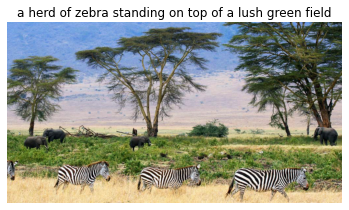

In [33]:
caption('test/savana.jpg')

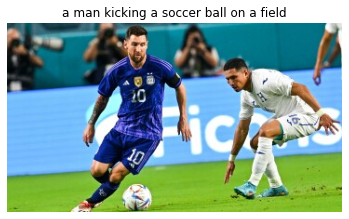

In [34]:
caption('test/messi.jpg')